Cell 0 — Imports

In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import json
from datetime import datetime


Cell 1 — Step 1 helpers (global state)

In [2]:
def simulate_global_state(T=20000, D=256, seed=123, mu=-1.5, sigma=0.3, sigma_drift=0.001):
    rng = np.random.default_rng(seed)
    alpha = rng.normal(mu, sigma, size=D)
    beta  = rng.normal(mu, sigma, size=D)
    eps = np.zeros(D)
    X = np.zeros((T, D), dtype=np.int8)
    X[0] = rng.binomial(1, 0.5, size=D)
    for t in range(1, T):
        eps += rng.normal(0, sigma_drift, size=D)
        p = 1 / (1 + np.exp(-(alpha + eps)))
        q = 1 / (1 + np.exp(-(beta  + eps)))
        X[t] = rng.binomial(1, np.where(X[t-1]==0, p, 1-q))
    return X


Cell 2 — Step 2 helpers (nodes + signals)

In [3]:
def construct_nodes(D=256, K=40, subset_size=25, overlap_target=5, seed=123):
    rng = np.random.default_rng(seed)
    subsets = [set(rng.choice(D, subset_size, replace=False))]
    for _ in range(1, K):
        base_subset = subsets[rng.integers(len(subsets))]
        base = rng.choice(list(base_subset), overlap_target, replace=False)
        rest = rng.choice(list(set(range(D)) - set(base)), subset_size - overlap_target, replace=False)
        subsets.append(set(base) | set(rest))
    return subsets

def compute_node_signals(X, subsets):
    Z = np.zeros((X.shape[0], len(subsets)), dtype=np.float32)
    for k, S in enumerate(subsets):
        Z[:, k] = X[:, list(S)].mean(axis=1)
    return Z


Cell 3 — Step 5 destruction helper (bit-flip)

In [4]:
def destroy_bitflip_X(X, delta, seed=999):
    rng = np.random.default_rng(seed)
    flips = rng.random(X.shape) < delta
    Xd = X.copy()
    Xd[flips] = 1 - Xd[flips]
    return Xd


Cell 4 — Step 4 dataset used for evaluation (masked windows)

In [5]:
class MaskedWindowDataset(Dataset):
    def __init__(self, Z, window=128, mask_ratio=0.15, seed=2):
        rng = np.random.default_rng(seed)
        T, K = Z.shape
        self.Z = Z.astype(np.float32)
        self.window = window
        self.N = T - window
        self.masks = rng.random((self.N, window, K)) < mask_ratio

    def __len__(self):
        return self.N

    def __getitem__(self, idx):
        x = self.Z[idx:idx+self.window].copy()
        m = self.masks[idx]
        y = x.copy()
        x[m] = 0.0
        return torch.from_numpy(x), torch.from_numpy(m), torch.from_numpy(y)


Cell 5 — Model class (must match training)

In [6]:
class MaskedTimeTransformer(nn.Module):
    def __init__(self, K, window=128, d_model=128, nhead=4, num_layers=3, dim_ff=256, dropout=0.1):
        super().__init__()
        self.in_proj = nn.Linear(K, d_model)
        self.pos_emb = nn.Parameter(torch.randn(window, d_model) * 0.02)

        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_ff,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=num_layers)
        self.out_proj = nn.Linear(d_model, K)

    def forward(self, x):
        B, L, _ = x.shape
        h = self.in_proj(x) + self.pos_emb[:L].unsqueeze(0)
        h = self.encoder(h)
        return self.out_proj(h)


Cell 6 — Load model weights

In [7]:
device = "cuda" if torch.cuda.is_available() else "cpu"

K = 40
window = 128
mask_ratio = 0.15

model = MaskedTimeTransformer(K=K, window=window).to(device)
model.load_state_dict(torch.load("run1_clean_model.pt", map_location=device))
model.eval()

print("loaded on", device)


loaded on cpu


C:\Users\user\AppData\Local\Temp\ipykernel_30608\2184215657.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("run1_clean_model.pt", map_l

Cell 7 — Step 7 info-theory utilities + collectors + baseline

In [8]:
def discretize(x, bins):
    return np.digitize(x, bins) - 1

def entropy_from_counts(counts):
    p = counts / counts.sum()
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))

def mutual_information(x, y):
    xy = np.stack([x, y], axis=1)
    _, cxy = np.unique(xy, axis=0, return_counts=True)
    _, cx = np.unique(x, return_counts=True)
    _, cy = np.unique(y, return_counts=True)
    Hx = entropy_from_counts(cx)
    Hy = entropy_from_counts(cy)
    Hxy = entropy_from_counts(cxy)
    return Hx + Hy - Hxy

def H_from_samples(x):
    _, cx = np.unique(x, return_counts=True)
    return entropy_from_counts(cx)

@torch.no_grad()
def collect_masked_predictions(model, loader, device):
    model.eval()
    z_true, z_pred = [], []
    for xb, mb, yb in loader:
        xb = xb.to(device).float()
        m = mb.numpy().astype(bool)
        y = yb.numpy().astype(np.float32)
        yhat = model(xb).cpu().numpy().astype(np.float32)
        z_true.append(y[m])
        z_pred.append(yhat[m])
    return np.concatenate(z_true), np.concatenate(z_pred)

def baseline_predict_window_node_mean(x_masked_np):
    node_means = x_masked_np.mean(axis=1, keepdims=True)  # (B,1,K)
    return np.repeat(node_means, x_masked_np.shape[1], axis=1)

def collect_baseline_window_predictions(val_loader):
    z_true, z_pred = [], []
    for xb, mb, yb in val_loader:
        x = xb.numpy().astype(np.float32)
        m = mb.numpy().astype(bool)
        y = yb.numpy().astype(np.float32)
        yhat = baseline_predict_window_node_mean(x)
        z_true.append(y[m])
        z_pred.append(yhat[m])
    return np.concatenate(z_true), np.concatenate(z_pred)


Cell 8 — Build base data once (for Step 7 sweeps)

In [9]:
T = 20000
seed_world = 123
seed_nodes = 123

X = simulate_global_state(T=T, seed=seed_world)
subsets = construct_nodes(K=K, seed=seed_nodes)
Z = compute_node_signals(X, subsets)
split = int(0.8 * Z.shape[0])

bins = np.linspace(0, 1, 21)


Cell 9 ** — Step 7 sigma_drift sweep (you edit deltas here)

In [10]:
import numpy as np
from torch.utils.data import DataLoader

# Fixed setting (must match training/model)
T = 20000
K = 40
window = 128
mask_ratio = 0.15
bins = np.linspace(0, 1, 21)

seed_world = 123
seed_nodes = 123
seed_destroy = 999 # not used here, but keep style consistent

# important: keep node subsets fixed so comparisons are apples-to-apples
X0 = simulate_global_state(T=T, seed=seed_world, sigma_drift=0.001)
subsets = construct_nodes(K=K, seed=seed_nodes)

# train/val split rule reused
# (we recompute split on each new Z because T is same anyway)
def eval_on_sigma(model, sigma_drift):
    X = simulate_global_state(T=T, seed=seed_world, sigma_drift=sigma_drift)
    Z = compute_node_signals(X, subsets)
    split = int(0.8 * Z.shape[0])

    Z_val = Z[split - window:]
    val_ds = MaskedWindowDataset(Z_val, window=window, mask_ratio=mask_ratio, seed=2)
    val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)

    # transformer
    zt_tf, zp_tf = collect_masked_predictions(model, val_loader, device)
    zt_tf_d = discretize(zt_tf, bins)
    zp_tf_d = discretize(zp_tf, bins)

    H_true = H_from_samples(zt_tf_d)
    MI_tf = mutual_information(zt_tf_d, zp_tf_d)
    R_tf = MI_tf / H_true if H_true > 1e-12 else 0.0

    # baseline
    zt_b, zp_b = collect_baseline_window_predictions(val_loader)
    zt_b_d = discretize(zt_b, bins)
    zp_b_d = discretize(zp_b, bins)

    MI_b = mutual_information(zt_b_d, zp_b_d)
    R_b = MI_b / H_true if H_true > 1e-12 else 0.0

    return {
        "sigma_drift": float(sigma_drift),
        "H_true": float(H_true),
        "MI_transformer": float(MI_tf),
        "R_transformer": float(R_tf),
        "MI_baseline_window": float(MI_b),
        "R_baseline_window": float(R_b),
    }

# dirft sweep grid (log-ish spacing is best)
sigmas = [0.0000, 0.0005, 0.001, 0.002, 0.004, 0.008, 0.016]

results_drift = []
for s in sigmas:
    results_drift.append(eval_on_sigma(model, s))

results_drift

[{'sigma_drift': 0.0,
  'H_true': 2.9880107380611354,
  'MI_transformer': 0.05399586573532389,
  'R_transformer': 0.018070840592213134,
  'MI_baseline_window': 0.015426229363089128,
  'R_baseline_window': 0.0051627088104438746},
 {'sigma_drift': 0.0005,
  'H_true': 2.9888837702568805,
  'MI_transformer': 0.05210607241088727,
  'R_transformer': 0.01743328828287257,
  'MI_baseline_window': 0.01660902484939264,
  'R_baseline_window': 0.005556932328608139},
 {'sigma_drift': 0.001,
  'H_true': 2.9844851292032937,
  'MI_transformer': 0.056133810959317465,
  'R_transformer': 0.018808541014343184,
  'MI_baseline_window': 0.01603408155057373,
  'R_baseline_window': 0.005372478285678045},
 {'sigma_drift': 0.002,
  'H_true': 2.9786730561082866,
  'MI_transformer': 0.05269636737089556,
  'R_transformer': 0.017691222359175172,
  'MI_baseline_window': 0.014930558052014042,
  'R_baseline_window': 0.005012486355760441},
 {'sigma_drift': 0.004,
  'H_true': 2.9878442889531716,
  'MI_transformer': 0.0538

Cell 10 ** — Plot + save (end of notebook)

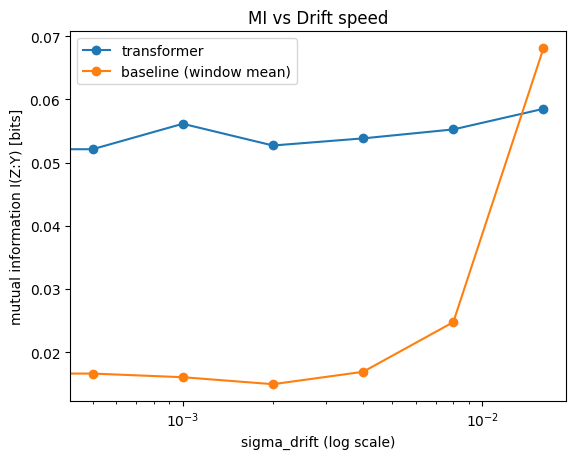

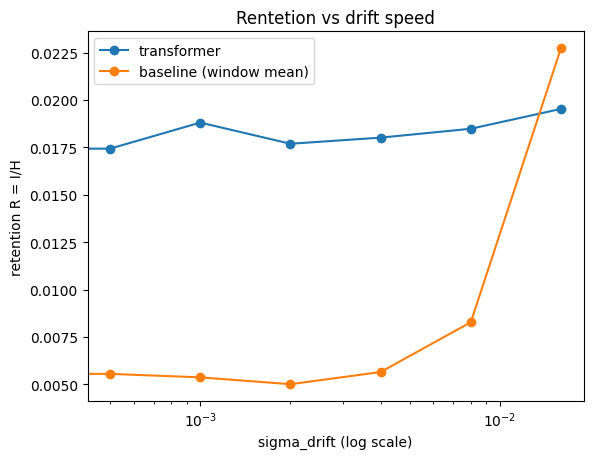

In [12]:
import matplotlib.pyplot as plt

s = [r["sigma_drift"] for r in results_drift]
mi_tf = [r["MI_transformer"] for r in results_drift]
mi_b = [r["MI_baseline_window"] for r in results_drift]
r_tf = [r["R_transformer"] for r in results_drift]
r_b = [r["R_baseline_window"] for r in results_drift]

plt.figure()
plt.plot(s, mi_tf, marker="o")
plt.plot(s, mi_b, marker="o")
plt.xscale("log")
plt.xlabel("sigma_drift (log scale)")
plt.ylabel("mutual information I(Z:Y) [bits]")
plt.title("MI vs Drift speed")
plt.legend(["transformer", "baseline (window mean)"])
plt.show()

plt.figure()
plt.plot(s, r_tf, marker="o")
plt.plot(s, r_b, marker="o")
plt.xscale("log")
plt.xlabel("sigma_drift (log scale)")
plt.ylabel("retention R = I/H")
plt.title("Rentetion vs drift speed")
plt.legend(["transformer", "baseline (window mean)"])
plt.show()

There is no σ* at which information collapses; instead, the system transitions from a representation-limited regime to a signal-dominated regime.

We find that increasing drift speed does not monotonically degrade predictive performance. Instead, at high drift rates the system enters a low-complexity regime in which transition probabilities saturate, leading to increased predictability and synchronization across nodes. In this regime, simple averaging becomes near-optimal and the transformer’s advantage disappears without a collapse in information.

In [13]:
import json
from datetime import datetime

# ---- CONFIG--------
config = {
    # data/generator
    "scenario": "sigma_drift_sweep",
    "T": T,
    "D": 256,
    "K": K,
    "subset_size": 25,
    "overlap_target": 5,
    "seed_world": seed_world,
    "seed_world": seed_nodes,

    # evaluation protocol
    "window": window,
    "mask_ratio": mask_ratio,
    "mask_seed": 2,
    "train_val_split": 0.8,
    "bins": bins.tolist(),

    # sweep
    "sigmas": [r["sigma_drift"] for r in results_drift],

    # model_file
    "model_weights": "run1_clean_model.pt",

    # model hyperparameters (must match how we trained)
    "model_hparams": {
        "d_model": 128,
        "nhead": 4,
        "num_layers": 3,
        "dim_ff": 256,
        "dropout": 0.1
    }
}

run = {
    "config": config,
    "results": results_drift
}

# ---- save ----
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
fname = f"drift_sweep_run_{stamp}.json"

with open(fname, "w") as f:
    json.dump(run, f, indent=2)

print("saved:", fname)

saved: drift_sweep_run_20260201_190247.json


In [15]:
import csv

csv_name = fname.replace(".json", ".csv")
keys = results_drift[0].keys()

with open(csv_name, "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=keys)
    w.writeheader()
    w.writerows(results_drift)

print("saved:", csv_name)


saved: drift_sweep_run_20260201_190247.csv
